In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import fetch_20newsgroups
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.decomposition import TruncatedSVD
from sklearn.metrics.pairwise import cosine_similarity

In [2]:
cats = ["sci.space", "rec.sport.hockey", "comp.graphics", "talk.politics.mideast"]
data = fetch_20newsgroups(subset="train", categories=cats, remove=("headers", "footers", "quotes"))
docs, y = data.data[:1500], data.target[:1500]

vec = TfidfVectorizer(stop_words="english", max_df=0.5, min_df=5)
X = vec.fit_transform(docs)
print("Document-term matrix:", X.shape)

Document-term matrix: (1500, 4981)


In [3]:
k = 4
svd = TruncatedSVD(n_components=k, random_state=42)
Z = svd.fit_transform(X)              # documents in latent space
print("Explained variance ratio:", svd.explained_variance_ratio_.round(3))

Explained variance ratio: [0.004 0.009 0.008 0.007]


In [4]:
terms = np.array(vec.get_feature_names_out())
for i, comp in enumerate(svd.components_):
    print(f"Topic {i}:", ", ".join(terms[comp.argsort()[::-1][:8]]))

Topic 0: like, people, space, don, know, just, think, israel
Topic 1: armenian, israel, armenians, turkish, jews, israeli, people, armenia
Topic 2: game, team, hockey, play, players, games, nhl, detroit
Topic 3: israel, israeli, jews, arab, arabs, lebanese, lebanon, adam


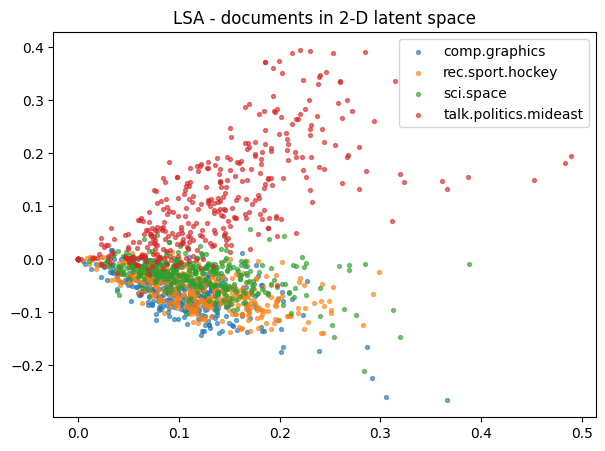

In [5]:
svd2 = TruncatedSVD(n_components=2, random_state=42)
Z2 = svd2.fit_transform(X)
plt.figure(figsize=(7, 5))
for c, name in enumerate(data.target_names):
    m = y == c
    plt.scatter(Z2[m, 0], Z2[m, 1], s=8, label=name, alpha=0.6)
plt.legend(); plt.title("LSA - documents in 2-D latent space"); plt.show()

In [6]:
query = ["spacecraft orbit satellite launch"]
q = svd.transform(vec.transform(query))
sims = cosine_similarity(q, Z)[0]
for i in sims.argsort()[::-1][:3]:
    print(f"{sims[i]:.3f} | [{data.target_names[y[i]]}] {docs[i][:120]!r}")

0.997 | [sci.space] 'Archive-name: space/net\nLast-modified: $Date: 93/04/01 14:39:15 $\n\nNETWORK RESOURCES\n\nOVERVIEW\n\n    You may be reading t'
0.997 | [sci.space] 'I am posting this for a friend without internet access. Please inquire\nto the phone number and address listed.\n---------'
0.996 | [sci.space] ': Announce that a reward of $1 billion would go to the first corporation \n: who successfully keeps at least 1 person ali'
